In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

names = ["baseline", "xgboost", "keras", "fastai", "tabnet", "lightning"]
frames = []
for n in names:
    path = f"../results/{n}_results.csv"
    print(n, os.path.exists(path))
    frames.append(pd.read_csv(path, index_col=[0, 1]))

allres = pd.concat(frames).sort_index()
print(allres.shape)   # expect 24 rows: 12 per dataset

baseline True
xgboost True
keras True
fastai True
tabnet True
lightning True
(20, 5)


In [2]:
cols = ["RMSE", "MAE", "R2", "R2_OOS", "DirAcc"]
for k in ["base", "tech"]:
    t = allres.loc[k, cols].sort_values("RMSE")
    print(f"\n=== {k} features ===")
    print(t.round(4))
    t.round(4).to_csv(f"../results/final_comparison_{k}.csv")


=== base features ===
                         RMSE     MAE      R2  R2_OOS  DirAcc
model                                                        
fastai tabular         0.0363  0.0261  0.0218  0.0230  0.5086
PyTorch Lightning MLP  0.0363  0.0260  0.0217  0.0229  0.4743
Linear regression      0.0364  0.0265  0.0167  0.0179  0.4514
Keras MLP              0.0366  0.0261  0.0071  0.0083  0.5257
Ridge                  0.0366  0.0260  0.0060  0.0072  0.5086
XGBoost (tuned)        0.0366  0.0261  0.0059  0.0071  0.5429
Train mean             0.0367  0.0260 -0.0012  0.0000  0.5200
Zero forecast          0.0368  0.0258 -0.0078 -0.0065  0.4800
TabNet                 0.0370  0.0260 -0.0175 -0.0163  0.5029
XGBoost (default)      0.0381  0.0278 -0.0808 -0.0795  0.4914

=== tech features ===
                         RMSE     MAE      R2  R2_OOS  DirAcc
model                                                        
TabNet                 0.0364  0.0259  0.0253  0.0263  0.5434
Linear regression      0

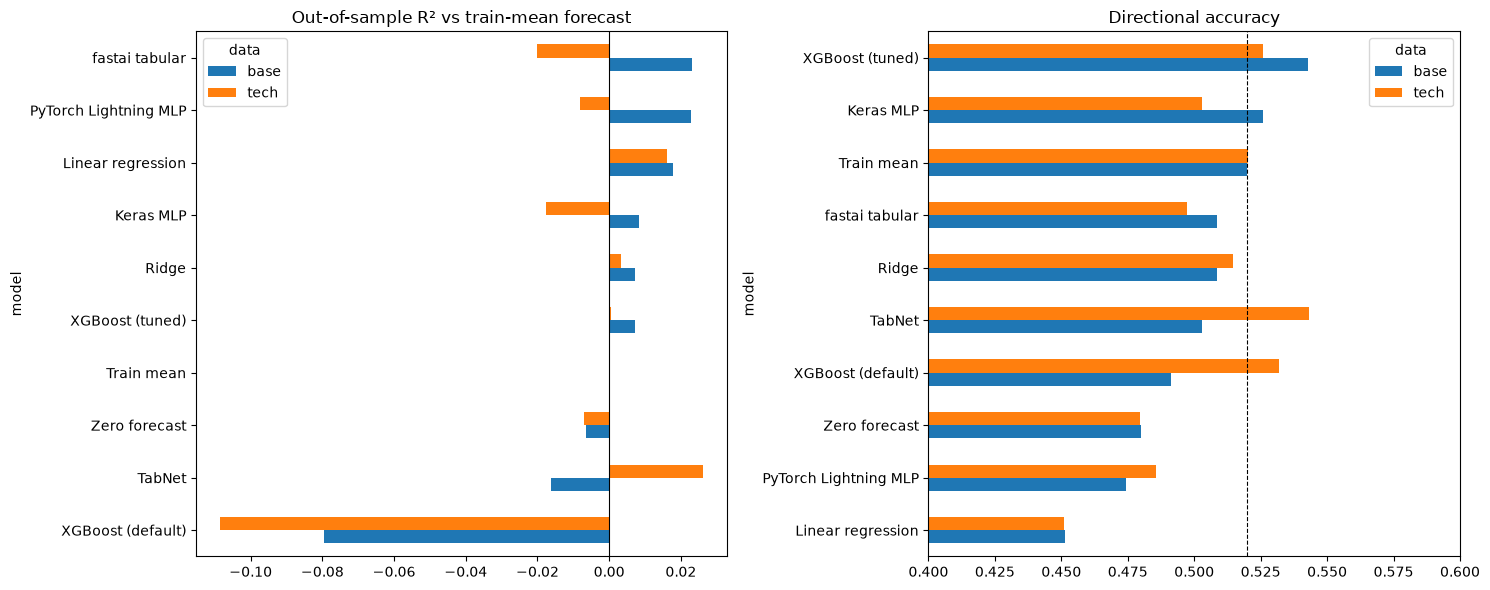

In [3]:
os.makedirs("../figures", exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

r2 = allres["R2_OOS"].unstack(0).sort_values("base")
r2.plot.barh(ax=ax[0], title="Out-of-sample R² vs train-mean forecast")
ax[0].axvline(0, color="k", lw=0.8)

da = allres["DirAcc"].unstack(0).sort_values("base")
da.plot.barh(ax=ax[1], title="Directional accuracy")
ax[1].axvline(0.52, color="k", ls="--", lw=0.8)   # always guessing "up"
ax[1].set_xlim(0.4, 0.6)

plt.tight_layout()
plt.savefig("../figures/19_model_comparison.png", dpi=150)
plt.show()

In [4]:
for k in ["base", "tech"]:
    r = allres.loc[k, "RMSE"]
    print(f"{k}: min {r.min():.4f}  max {r.max():.4f}  "
          f"spread {r.max() - r.min():.4f}  "
          f"without default XGBoost: {r.drop('XGBoost (default)').max() - r.min():.4f}")

# Does adding technical indicators help? (positive = tech better)
delta = allres["R2_OOS"].unstack(0)
delta["tech_minus_base"] = delta["tech"] - delta["base"]
print(delta.round(4))

base: min 0.0363  max 0.0381  spread 0.0019  without default XGBoost: 0.0007
tech: min 0.0364  max 0.0388  spread 0.0024  without default XGBoost: 0.0009
data                     base    tech  tech_minus_base
model                                                 
Keras MLP              0.0083 -0.0176          -0.0259
Linear regression      0.0179  0.0162          -0.0017
PyTorch Lightning MLP  0.0229 -0.0083          -0.0311
Ridge                  0.0072  0.0033          -0.0039
TabNet                -0.0163  0.0263           0.0425
Train mean             0.0000  0.0000           0.0000
XGBoost (default)     -0.0795 -0.1085          -0.0290
XGBoost (tuned)        0.0071  0.0004          -0.0067
Zero forecast         -0.0065 -0.0071          -0.0005
fastai tabular         0.0230 -0.0200          -0.0431


In [5]:
models = ["Linear regression", "Ridge", "XGBoost (tuned)", "Keras MLP",
          "fastai tabular", "TabNet", "PyTorch Lightning MLP"]
tmpl = pd.DataFrame({
    "model": models,
    "Simplicity (1-5)": "", "Simplicity: why": "",
    "Transparency (1-5)": "", "Transparency: why": "",
    "Efficacy (1-5)": "", "Efficacy: why": "",
})
tmpl.to_csv("../results/ste_ratings_TEMPLATE.csv", index=False)
tmpl

,model,Simplicity (1-5),Simplicity: why,Transparency (1-5),Transparency: why,Efficacy (1-5),Efficacy: why
0,Linear regression,,,,,,
1,Ridge,,,,,,
2,XGBoost (tuned),,,,,,
3,Keras MLP,,,,,,
4,fastai tabular,,,,,,
5,TabNet,,,,,,
6,PyTorch Lightning MLP,,,,,,
